# Homework Reflection: Weeks 5-8

### Imports

In [37]:
from IPython.display import Image, display

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

### Homework Reflection 5

*1. Draw a diagram for the following negative feedback loop: Sweating causes body temperature to decrease.  High body temperature causes sweating. A negative feedback loop means that one thing increases another while the second thing decreases the first. Remember that we are using directed acyclic graphs where two things cannot directly cause each other.*

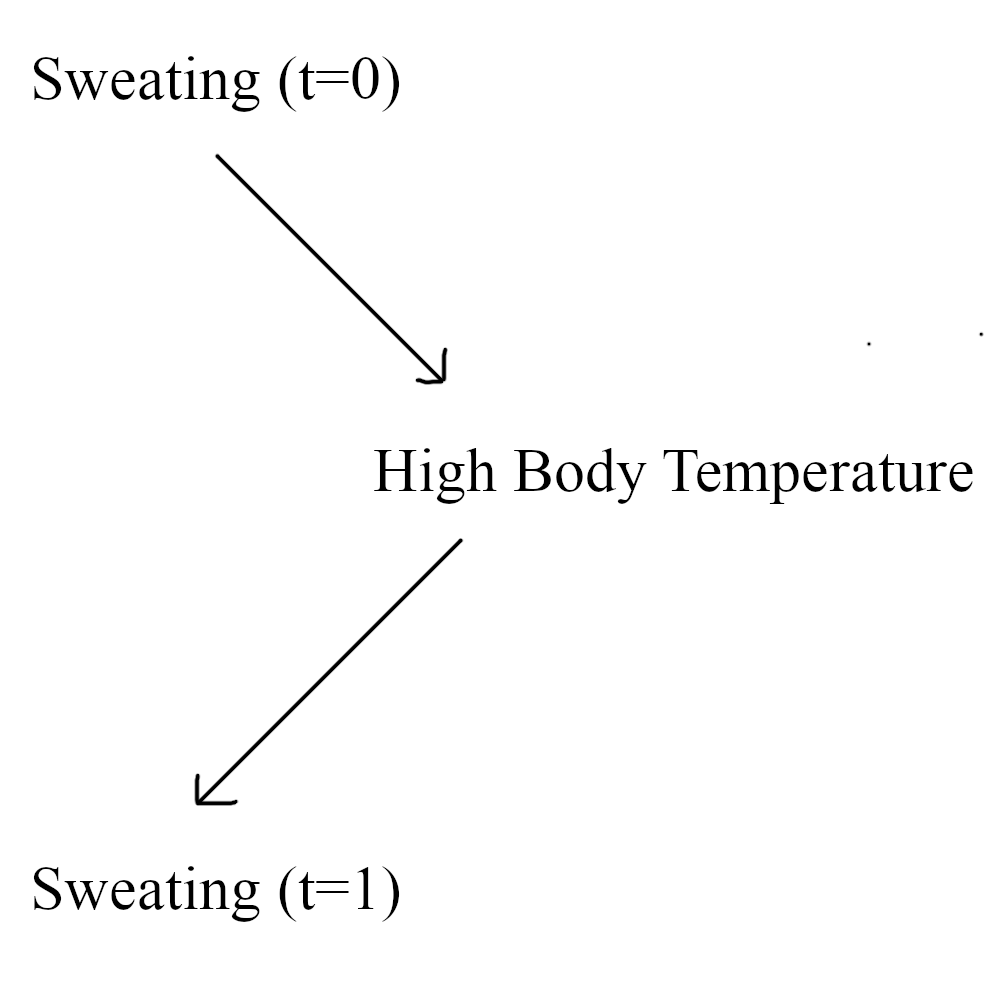

In [41]:
display(Image(filename='assets/dag.png'))

*2. Describe an example of a positive feedback loop.  This means that one things increases another while the second things also increases the first.*

A simple example of a positive feedback loop could be smiling makes you feel happy and being happy causes you to smile. This is a positive feedback loop because smiling increases happiness, which in turn increases smiling.

:)

*3. Draw a diagram for the following situation: Lightning storms frighten away deer and bears, decreasing their population, and cause flowers to grow, increasing their population. Bears eat deer, decreasing their population. Deer eat flowers, decreasing their population.*

*Write a dataset that simulates this situation.  (Show the code.) Include noise / randomness in all cases.*

*Identify a backdoor path with one or more confounders for the relationship between deer and flowers.*

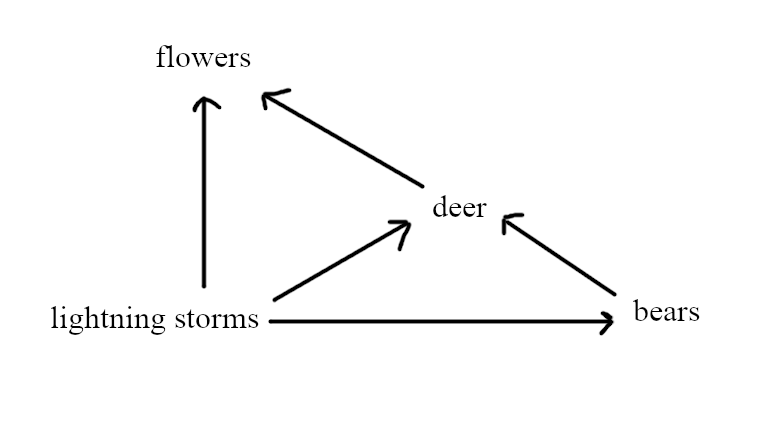

In [40]:
display(Image(filename='./assets/dag_2.png'))

In [18]:
import numpy as np
import pandas as pd

n = 100
start_value = 100

lightning = np.random.binomial(1, 0.3, n)

bear = start_value - 5 * lightning + np.random.normal(0, 5, n)
bear = np.clip(bear, 0, None)

deer = start_value - 5 * lightning - 0.25 * bear + np.random.normal(0, 5, n)
deer = np.clip(deer, 0, None)

flower = start_value - 1.15 * deer + 5 * lightning + np.random.normal(0, 5, n)
flower = np.clip(flower, 0, None)

df = pd.DataFrame({
    "lightning": lightning,
    "bear": bear,
    "deer": deer,
    "flower": flower
})

print(df.head())

   lightning        bear       deer     flower
0          0  111.494491  72.791226  16.168317
1          1   93.185807  68.202944  37.277966
2          0   97.772487  81.532111  14.875788
3          0  107.266922  65.567335  26.779183
4          0  107.897861  70.230926  19.424453


The backdoor path between deer and flowers is:

<center>deer <- lighting storms -> flowers</center>

with the confounder being lightning storms

*4. Draw a diagram for a situation of your own invention.  The diagram should include at least four nodes, one confounder, and one collider.  Be sure that it is acyclic (no loops).  Which node would say is most like a treatment (X)?  Which is most like an outcome (Y)?*

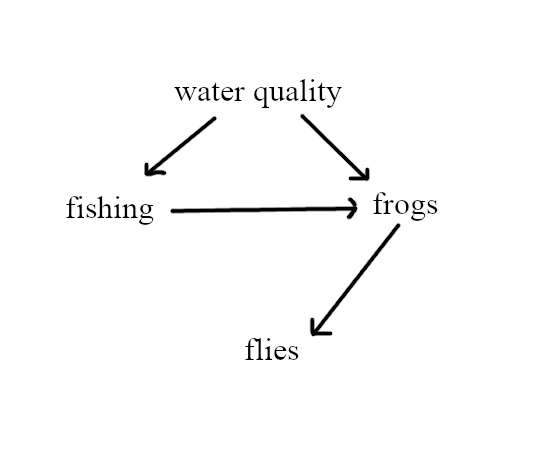

In [42]:
display(Image(filename='assets/dag_3.png'))

The relationship being modelled here is as follows:
 * water quality increases fishing
 * water quality increases frogs
 * fishing decreases frogs
 * frogs decrease the number of flies
The confounder in this scenario is water quality while the collider is frogs.

The most treatment-like node in this scenario I would say is `fishing`, while the outcome is `flies`. The model created would show the effect of fishing on various wildlife populations.

### Homework Reflection 6

*1. What is a potential problem with computing the Marginal Treatment Effect simply by comparing each untreated item to its counterfactual and taking the maximum difference?  (Hint: think of statistics here.  Consider that only the most extreme item ends up being used to estimate the MTE.  That's not necessarily a bad thing; the MTE is supposed to come from the untreated item that will produce the maximum effect.  But there is nevertheless a problem.)*

*Possible answer: We are likely to find the item with the most extreme difference, which may be high simply due to randomness.*

*(Please explain / justify this answer, or give a different one if you can think of one.)*

The answer of being likely to find an extreme difference, which may be high simply due to randomness is a good answer.

By taking the maximum difference, we are not getting a good representation of the dataset at large. As seen in the next question, taking a high percentile is more effective because it still shows the better outcome while being more representative of the dataset.

*2. Propose a solution that remedies this problem and write some code that implements your solution.*

*It's very important here that you clearly explain what your solution will do.*

*Possible answer: maybe we could take the 90th percentile of the treatment effect and use it as a proxy for the Marginal Treatment Effect.*

In [ ]:
# Code to take the 90th and 80th percentile of the treatment effect
df = pd.read_csv('datasets/homework_6.1.csv')

X_features = df['Z'].values.reshape(-1, 1)

treated = df['X'] == 1
untreated = df['X'] == 0

model = LinearRegression()

model1 = model.__class__(**model.get_params())
model1.fit(X_features[treated], df.loc[treated, 'Y'])

model0 = model.__class__(**model.get_params())
model0.fit(X_features[untreated], df.loc[untreated, 'Y'])

Y1_hat = model1.predict(X_features)
Y0_hat = model0.predict(X_features)

treatment_effect = Y1_hat - Y0_hat
MTE_max = treatment_effect.max()
MTE_p90 = pd.Series(treatment_effect).quantile(0.9)
MTE_p80 = pd.Series(treatment_effect).quantile(0.8)

print(f"MTE (max): {MTE_max:.2f}")
print(f"MTE (90th percentile): {MTE_p90:.2f}")
print(f"MTE (80th percentile): {MTE_p80:.2f}")

MTE (max): 2.20
MTE (90th percentile): 2.11
MTE (80th percentile): 2.01


Using the dataset from homework 6 with derived counterfactuals does not show major changes, but nonetheless it does show that as we take the nth percentile, we are decreasing. For experimentation, I included the 80th percentile to show how it would further decrease. In a real scenario the percentile could be tweaked depending on desired information/dataset requirements.

### Homework Reflection 7

*1. Create a linear regression model involving a confounder that is left out of the model.  Show whether the true correlation between $$X$$ and $$Y$$ is overestimated, underestimated, or neither.  Explain in words why this is the case for the given coefficients you have chosen.*

In [30]:
# Create Synthetic data
np.random.seed(42)
n = 500

Z = np.random.normal(loc=50, scale=10, size=n)

X = 5 + 0.75 * Z + np.random.normal(0, 5, n)

Y = 15 + 0.5 * X + 3 * Z + np.random.normal(0, 5, n)

df = pd.DataFrame({'X': X, 'Y': Y, 'Z': Z})

#df.head()

# Create model (without confounder)
model_no_confounder = sm.OLS(df['Y'], df['X']).fit()
print(model_no_confounder.summary())

# Create model (with confounder)
model_confounder = sm.OLS(df['Y'], df.drop(columns=['Y'])).fit()
print(model_confounder.summary())

                                 OLS Regression Results                                
Dep. Variable:                      Y   R-squared (uncentered):                   0.990
Model:                            OLS   Adj. R-squared (uncentered):              0.990
Method:                 Least Squares   F-statistic:                          4.819e+04
Date:                Sun, 12 Jul 2026   Prob (F-statistic):                        0.00
Time:                        23:07:11   Log-Likelihood:                         -2187.9
No. Observations:                 500   AIC:                                      4378.
Df Residuals:                     499   BIC:                                      4382.
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

When creating the model without the confounder, the X coefficient has to overcompensate for the exclusion of the confounder. This results in a much larger coefficient and therefore a larger correlation than the actual reality of the scenario. This is further demonstrated by X decreasing greatly to its true value when we perform regression including the confounder.

*2. Perform a linear regression analysis in which one of the coefficients is zero, e.g.*

```
W = [noise]
X = [noise]
Y = 2 * X + [noise]
```

*And compute the p-value of a coefficient - in this case, the coefficient of W.*  

*(This is the likelihood that the estimated coefficient would be as high or low as it is, given that the actual coefficient is zero.)*

*If the p-value is less than 0.05, this ordinarily means that we judge the coefficient to be nonzero (incorrectly, in this case.)*

*Run the analysis 1000 times and report the best (smallest) p-value.*

*If the p-value is less than 0.05, does this mean the coefficient actually is nonzero?  What is the problem with repeating the analysis?*

In [36]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

n = 500
n_trials = 1000

p_values = []

for i in range(n_trials):
    rng = np.random.default_rng(i)

    W = rng.normal(loc=50, scale=10, size=n)
    X = rng.normal(loc=50, scale=10, size=n)
    Y = 2 * X + rng.normal(loc=50, scale=10, size=n)

    df = pd.DataFrame({'X': X, 'W': W, 'Y': Y})
    predictors = sm.add_constant(df[['X', 'W']])
    model = sm.OLS(df['Y'], predictors).fit()

    p_values.append(model.pvalues['W'])

p_values = np.array(p_values)

best_pvalue = p_values.min()

print(f"p-value (average): {p_values.mean():.6f}")
print(f"p-value (min): {best_pvalue:.6f}")

p-value (average): 0.501997
p-value (min): 0.002024


When running 1000 trials, we are able to see a small p-value (0.002). If we look at the mean p-value across the 1000 trials, we have a much higher (and reasonable) value of (0.5). The problem with this analysis is that we are essentially cherry-picking the result we are looking for both by running a large number of trials, and by taking the minimum value. This does not mean the coefficient is nonzero, we know this not to be the case, but rather that random noise can sometimes seem significant.

### Homework Reflection 8

*Include the code you used to solve Week 8's coding quiz problems and write about the obstacles / challenges / insights you encountered while solving them.*

**Code included in submission**

The most challenging part to me of homework 8 was question 3 asking you to estimate ATE using mahalanobis distance.

In order to calculate the mahalanobis distances for the full dataset I had to perform a nested iteration in which I could then utilize the imported `mahalanobis` function from `scipy.spatial.distance` referencing the inverted covariance matrix. When looking for resources online, most referenced other packages that were able to utilize parallel processing. In this case though creating the loop that calculated distances really helped contextualize it for me rather than simply importing a package.